In [1]:
# ============================================================
# Assignment 7 - FashionMNIST Autoencoders
# Personal Parameters
# ============================================================

SID4 = 9357
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6

CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print("SID4 :", SID4)
print("SEED :", SEED)
print("SLICE:", SLICE)
print("HP_ID:", HP_ID)
print("CLS_A:", CLS_A)
print("CLS_B:", CLS_B)

SID4 : 9357
SEED : 9357
SLICE: 357
HP_ID: 3
CLS_A: 7
CLS_B: 6


Imports and Reproducibility

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# More reproducible CUDA behavior
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("PyTorch version:", torch.__version__)

Device: cuda
PyTorch version: 2.11.0+cu130


Load FashionMNIST

In [3]:
# ============================================================
# Load FashionMNIST
# ============================================================

transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

BATCH_SIZE = 128

# Generator for reproducible shuffling
generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples :", len(test_dataset))
print("Image shape     :", train_dataset[0][0].shape)

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 208kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.85MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.8MB/s]

Training samples: 60000
Testing samples : 10000
Image shape     : torch.Size([1, 28, 28])


Display Sample FashionMNIST Images

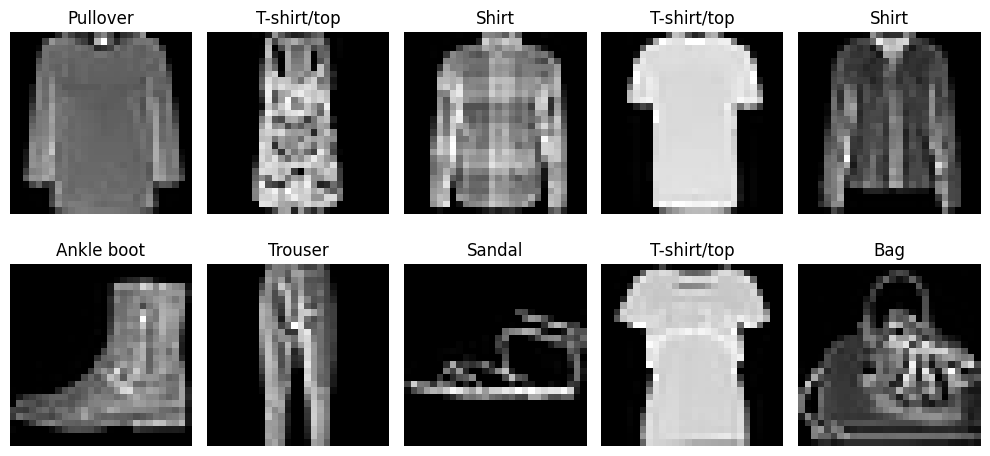

In [4]:
# ============================================================
# Visualize sample FashionMNIST images
# ============================================================

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

Fully Connected Autoencoder

In [5]:
# ============================================================
# Fully Connected Autoencoder
# ============================================================

class FCAutoencoder(nn.Module):
    def __init__(self, latent_dim=32):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)

        z = self.encoder(x)
        reconstructed = self.decoder(z)

        reconstructed = reconstructed.view(-1, 1, 28, 28)

        return reconstructed


LATENT_DIM = 32

fc_ae = FCAutoencoder(latent_dim=LATENT_DIM).to(device)

print(fc_ae)

num_params = sum(p.numel() for p in fc_ae.parameters())
print(f"\nTrainable parameters: {num_params:,}")

FCAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

Trainable parameters: 439,728


FC-AE Training Setup

In [6]:
# ============================================================
# FC-AE Training Configuration
# ============================================================

FC_LR = 1e-3
FC_EPOCHS = 20

fc_criterion = nn.MSELoss()

fc_optimizer = optim.Adam(
    fc_ae.parameters(),
    lr=FC_LR
)

print("FC-AE configuration")
print("Learning rate:", FC_LR)
print("Epochs       :", FC_EPOCHS)
print("Batch size   :", BATCH_SIZE)
print("Latent dim   :", LATENT_DIM)
print("Loss         : MSE")
print("Optimizer    : Adam")

FC-AE configuration
Learning rate: 0.001
Epochs       : 20
Batch size   : 128
Latent dim   : 32
Loss         : MSE
Optimizer    : Adam


Train FC-AE

In [7]:
# ============================================================
# Train FC-AE
# ============================================================

fc_train_losses = []

for epoch in range(FC_EPOCHS):

    fc_ae.train()

    running_loss = 0.0

    for images, _ in train_loader:

        images = images.to(device)

        # Forward pass
        reconstructed = fc_ae(images)

        loss = fc_criterion(reconstructed, images)

        # Backpropagation
        fc_optimizer.zero_grad()
        loss.backward()
        fc_optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)

    fc_train_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{FC_EPOCHS}] "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch [01/20] Loss: 0.037297
Epoch [02/20] Loss: 0.020543
Epoch [03/20] Loss: 0.017816
Epoch [04/20] Loss: 0.016442
Epoch [05/20] Loss: 0.015418
Epoch [06/20] Loss: 0.014578
Epoch [07/20] Loss: 0.013894
Epoch [08/20] Loss: 0.013382
Epoch [09/20] Loss: 0.012950
Epoch [10/20] Loss: 0.012597
Epoch [11/20] Loss: 0.012305
Epoch [12/20] Loss: 0.012016
Epoch [13/20] Loss: 0.011751
Epoch [14/20] Loss: 0.011534
Epoch [15/20] Loss: 0.011304
Epoch [16/20] Loss: 0.011110
Epoch [17/20] Loss: 0.010936
Epoch [18/20] Loss: 0.010773
Epoch [19/20] Loss: 0.010611
Epoch [20/20] Loss: 0.010495


FC-AE Training Curve

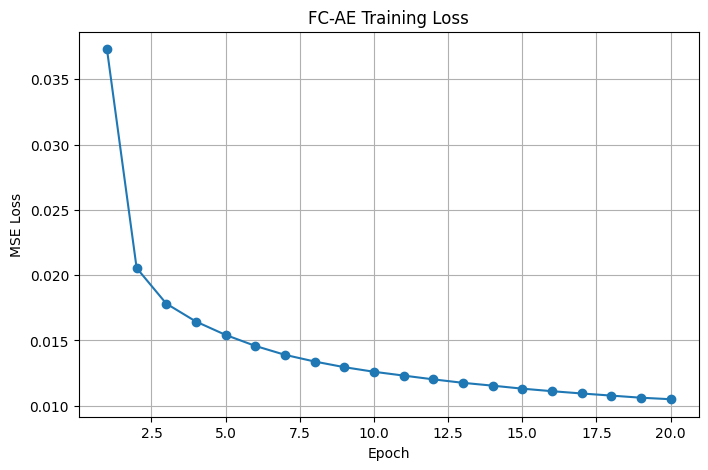

In [8]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, FC_EPOCHS + 1),
    fc_train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("FC-AE Training Loss")
plt.grid(True)

plt.show()

Evaluate FC-AE

In [9]:
# ============================================================
# Evaluate FC-AE on Test Dataset
# ============================================================

fc_ae.eval()

fc_test_loss = 0.0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        reconstructed = fc_ae(images)

        loss = fc_criterion(reconstructed, images)

        fc_test_loss += loss.item() * images.size(0)

fc_test_loss /= len(test_loader.dataset)

print(f"FC-AE Test Reconstruction MSE: {fc_test_loss:.6f}")

FC-AE Test Reconstruction MSE: 0.010688


FC-AE Reconstructions

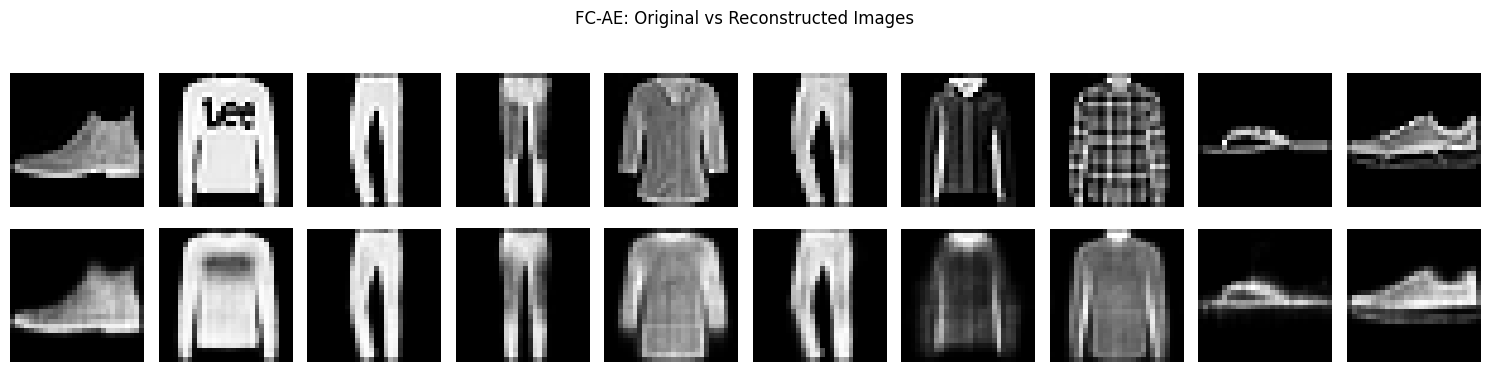

In [10]:
# ============================================================
# FC-AE Reconstruction Examples
# ============================================================

fc_ae.eval()

images, labels = next(iter(test_loader))

images = images[:10].to(device)

with torch.no_grad():
    reconstructed = fc_ae(images)

images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):

    # Original
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")

    # Reconstruction
    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("FC-AE", fontsize=12)

plt.suptitle("FC-AE: Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

Part B — Variational Autoencoder

VAE Model

In [11]:
# ============================================================
# Variational Autoencoder
# ============================================================

class VAE(nn.Module):

    def __init__(self, latent_dim=32):
        super().__init__()

        # Encoder
        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 64)

        # Latent distribution parameters
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        # Decoder
        self.fc3 = nn.Linear(latent_dim, 64)
        self.fc4 = nn.Linear(64, 256)
        self.fc5 = nn.Linear(256, 28 * 28)

    def encode(self, x):

        x = x.view(x.size(0), -1)

        h = F.relu(self.fc1(x))
        h = F.relu(self.fc2(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)

        eps = torch.randn_like(std)

        z = mu + eps * std

        return z

    def decode(self, z):

        h = F.relu(self.fc3(z))
        h = F.relu(self.fc4(h))

        reconstructed = torch.sigmoid(self.fc5(h))

        return reconstructed.view(-1, 1, 28, 28)

    def forward(self, x):

        mu, logvar = self.encode(x)

        z = self.reparameterize(mu, logvar)

        reconstructed = self.decode(z)

        return reconstructed, mu, logvar


vae = VAE(latent_dim=LATENT_DIM).to(device)

print(vae)

num_params = sum(p.numel() for p in vae.parameters())
print(f"\nTrainable parameters: {num_params:,}")

VAE(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc_mu): Linear(in_features=64, out_features=32, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=64, bias=True)
  (fc4): Linear(in_features=64, out_features=256, bias=True)
  (fc5): Linear(in_features=256, out_features=784, bias=True)
)

Trainable parameters: 441,808


VAE Loss

In [12]:
# ============================================================
# VAE Loss
# ============================================================

def vae_loss_function(reconstructed, original, mu, logvar):

    # Reconstruction loss
    reconstruction_loss = F.binary_cross_entropy(
        reconstructed,
        original,
        reduction="sum"
    )

    # KL divergence
    kl_divergence = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    total_loss = reconstruction_loss + kl_divergence

    return total_loss, reconstruction_loss, kl_divergence

VAE Training Setup

In [13]:
# ============================================================
# VAE Training Configuration
# ============================================================

VAE_LR = 1e-3
VAE_EPOCHS = 20

vae_optimizer = optim.Adam(
    vae.parameters(),
    lr=VAE_LR
)

print("VAE configuration")
print("Learning rate:", VAE_LR)
print("Epochs       :", VAE_EPOCHS)
print("Batch size   :", BATCH_SIZE)
print("Latent dim   :", LATENT_DIM)
print("Optimizer    : Adam")

VAE configuration
Learning rate: 0.001
Epochs       : 20
Batch size   : 128
Latent dim   : 32
Optimizer    : Adam


Train VAE

In [14]:
# ============================================================
# Train VAE
# ============================================================

vae_train_losses = []
vae_recon_losses = []
vae_kl_losses = []

for epoch in range(VAE_EPOCHS):

    vae.train()

    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0

    for images, _ in train_loader:

        images = images.to(device)

        vae_optimizer.zero_grad()

        reconstructed, mu, logvar = vae(images)

        loss, recon_loss, kl_loss = vae_loss_function(
            reconstructed,
            images,
            mu,
            logvar
        )

        loss.backward()

        vae_optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(train_loader.dataset)

    avg_loss = total_loss / n
    avg_recon = total_recon / n
    avg_kl = total_kl / n

    vae_train_losses.append(avg_loss)
    vae_recon_losses.append(avg_recon)
    vae_kl_losses.append(avg_kl)

    print(
        f"Epoch [{epoch + 1:02d}/{VAE_EPOCHS}] "
        f"Total: {avg_loss:.4f} | "
        f"Recon: {avg_recon:.4f} | "
        f"KL: {avg_kl:.4f}"
    )

Epoch [01/20] Total: 304.2463 | Recon: 292.7787 | KL: 11.4677
Epoch [02/20] Total: 263.4941 | Recon: 251.9506 | KL: 11.5435
Epoch [03/20] Total: 254.5513 | Recon: 243.7947 | KL: 10.7566
Epoch [04/20] Total: 250.3035 | Recon: 239.4702 | KL: 10.8332
Epoch [05/20] Total: 247.9293 | Recon: 236.8164 | KL: 11.1129
Epoch [06/20] Total: 246.3060 | Recon: 234.9103 | KL: 11.3957
Epoch [07/20] Total: 245.1774 | Recon: 233.5830 | KL: 11.5944
Epoch [08/20] Total: 244.3332 | Recon: 232.6093 | KL: 11.7239
Epoch [09/20] Total: 243.7331 | Recon: 231.9084 | KL: 11.8247
Epoch [10/20] Total: 243.1469 | Recon: 231.2327 | KL: 11.9142
Epoch [11/20] Total: 242.6678 | Recon: 230.6578 | KL: 12.0101
Epoch [12/20] Total: 242.1511 | Recon: 230.0282 | KL: 12.1229
Epoch [13/20] Total: 241.7676 | Recon: 229.5429 | KL: 12.2248
Epoch [14/20] Total: 241.4017 | Recon: 229.0905 | KL: 12.3112
Epoch [15/20] Total: 241.1302 | Recon: 228.7415 | KL: 12.3887
Epoch [16/20] Total: 240.8715 | Recon: 228.4454 | KL: 12.4260
Epoch [1

VAE Loss Curves

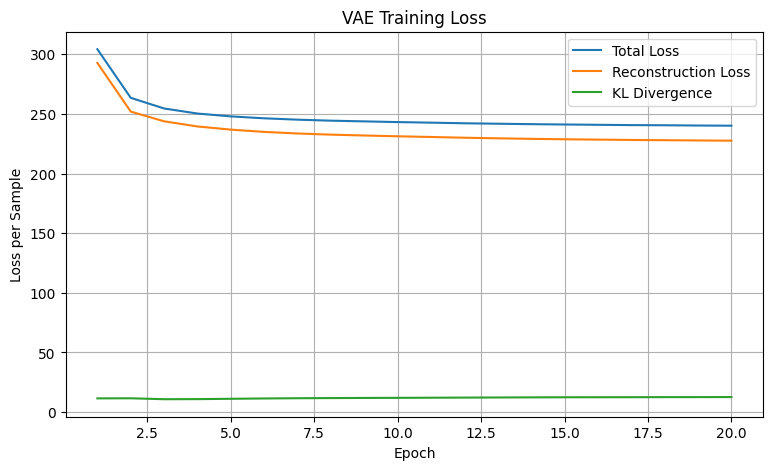

In [15]:
plt.figure(figsize=(9, 5))

epochs = range(1, VAE_EPOCHS + 1)

plt.plot(epochs, vae_train_losses, label="Total Loss")
plt.plot(epochs, vae_recon_losses, label="Reconstruction Loss")
plt.plot(epochs, vae_kl_losses, label="KL Divergence")

plt.xlabel("Epoch")
plt.ylabel("Loss per Sample")
plt.title("VAE Training Loss")
plt.legend()
plt.grid(True)

plt.show()

Evaluate VAE

In [16]:
# ============================================================
# Evaluate VAE
# ============================================================

vae.eval()

vae_test_total = 0.0
vae_test_recon = 0.0
vae_test_kl = 0.0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        reconstructed, mu, logvar = vae(images)

        loss, recon_loss, kl_loss = vae_loss_function(
            reconstructed,
            images,
            mu,
            logvar
        )

        vae_test_total += loss.item()
        vae_test_recon += recon_loss.item()
        vae_test_kl += kl_loss.item()

n = len(test_loader.dataset)

vae_test_total /= n
vae_test_recon /= n
vae_test_kl /= n

print(f"VAE Test Total Loss          : {vae_test_total:.4f}")
print(f"VAE Test Reconstruction Loss : {vae_test_recon:.4f}")
print(f"VAE Test KL Divergence       : {vae_test_kl:.4f}")

VAE Test Total Loss          : 242.0214
VAE Test Reconstruction Loss : 229.7402
VAE Test KL Divergence       : 12.2812


VAE Reconstructions

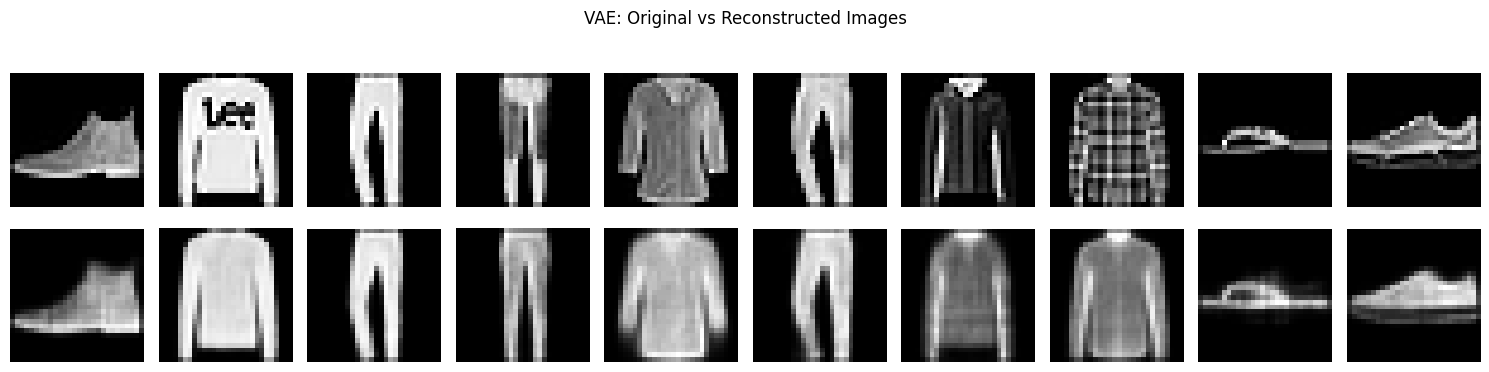

In [17]:
# ============================================================
# VAE Reconstruction Examples
# ============================================================

vae.eval()

images, labels = next(iter(test_loader))

images = images[:10].to(device)

with torch.no_grad():

    mu, logvar = vae.encode(images)

    # Use latent mean for deterministic reconstruction
    reconstructed = vae.decode(mu)

images = images.cpu()
reconstructed = reconstructed.cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 4))

for i in range(10):

    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=12)
axes[1, 0].set_ylabel("VAE", fontsize=12)

plt.suptitle("VAE: Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

Generate New Images with VAE

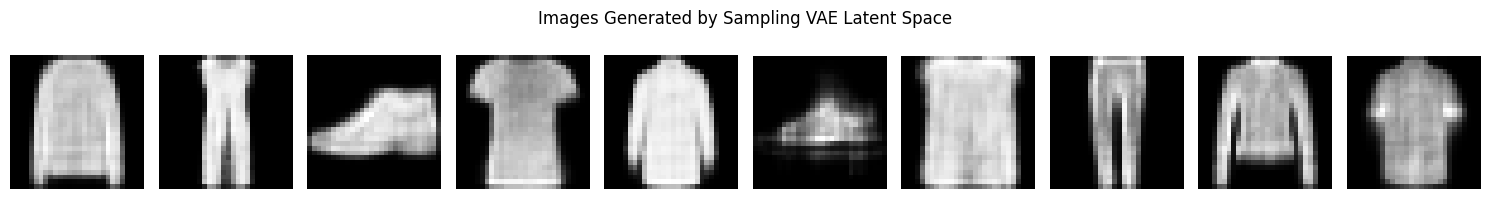

In [18]:
# ============================================================
# Generate New FashionMNIST-like Images with VAE
# ============================================================

vae.eval()

with torch.no_grad():

    z = torch.randn(
        10,
        LATENT_DIM,
        device=device
    )

    generated = vae.decode(z).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i in range(10):

    axes[i].imshow(
        generated[i].squeeze(),
        cmap="gray"
    )

    axes[i].axis("off")

plt.suptitle("Images Generated by Sampling VAE Latent Space")
plt.tight_layout()
plt.show()

Fair Reconstruction Comparison

In [19]:
# ============================================================
# Compare Reconstruction MSE Using the Same Metric
# ============================================================

fc_ae.eval()
vae.eval()

fc_mse_sum = 0.0
vae_mse_sum = 0.0
num_pixels = 0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        # FC-AE
        fc_reconstructed = fc_ae(images)

        # VAE
        mu, logvar = vae.encode(images)
        vae_reconstructed = vae.decode(mu)

        fc_mse_sum += F.mse_loss(
            fc_reconstructed,
            images,
            reduction="sum"
        ).item()

        vae_mse_sum += F.mse_loss(
            vae_reconstructed,
            images,
            reduction="sum"
        ).item()

        num_pixels += images.numel()

fc_mse = fc_mse_sum / num_pixels
vae_mse = vae_mse_sum / num_pixels

print("Common Test Reconstruction Metric")
print("---------------------------------")
print(f"FC-AE MSE : {fc_mse:.6f}")
print(f"VAE MSE   : {vae_mse:.6f}")

Common Test Reconstruction Metric
---------------------------------
FC-AE MSE : 0.010688
VAE MSE   : 0.015268


Side-by-Side Reconstruction Comparison

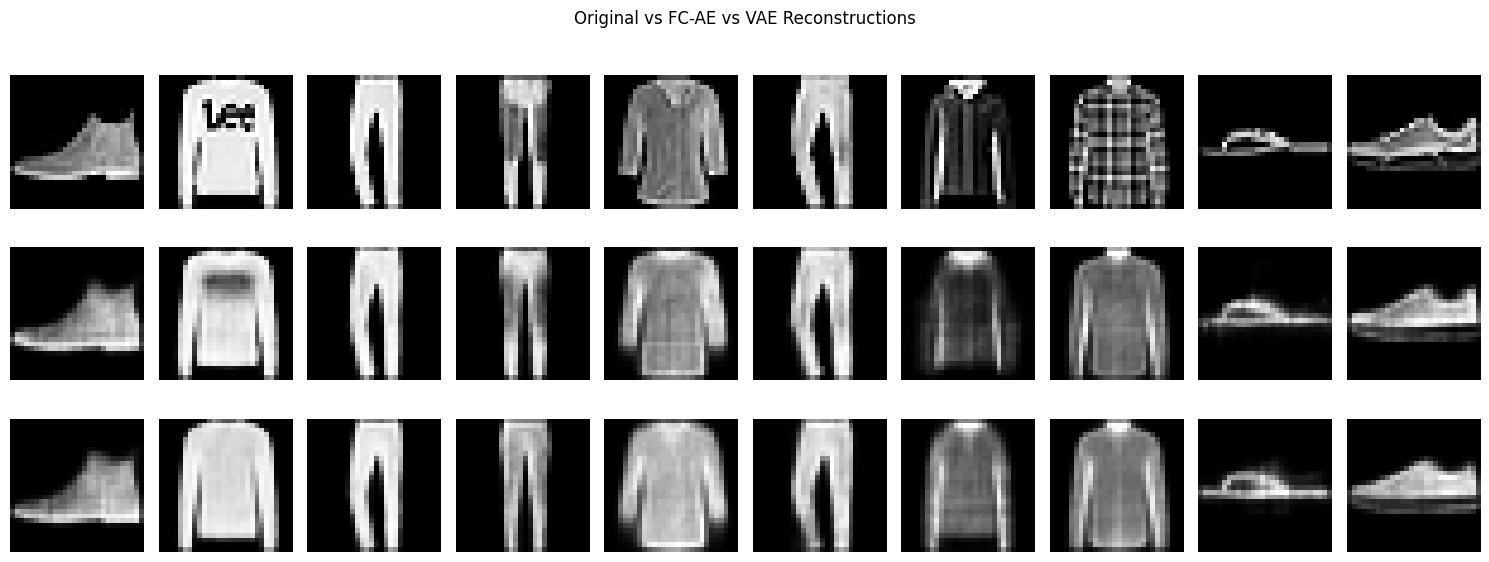

In [20]:
# ============================================================
# FC-AE vs VAE Reconstruction Comparison
# ============================================================

images, labels = next(iter(test_loader))
images = images[:10].to(device)

fc_ae.eval()
vae.eval()

with torch.no_grad():

    fc_recon = fc_ae(images)

    mu, logvar = vae.encode(images)
    vae_recon = vae.decode(mu)

images = images.cpu()
fc_recon = fc_recon.cpu()
vae_recon = vae_recon.cpu()

fig, axes = plt.subplots(3, 10, figsize=(15, 6))

for i in range(10):

    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(fc_recon[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")

    axes[2, i].imshow(vae_recon[i].squeeze(), cmap="gray")
    axes[2, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("FC-AE", fontsize=11)
axes[2, 0].set_ylabel("VAE", fontsize=11)

plt.suptitle("Original vs FC-AE vs VAE Reconstructions")
plt.tight_layout()
plt.show()

Results Summary

In [21]:
# ============================================================
# Final Results Summary
# ============================================================

print("=" * 55)
print("ASSIGNMENT 7 - AUTOENCODER RESULTS")
print("=" * 55)

print("\nPersonal Parameters")
print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")

print("\nFC-AE")
print(f"Final training MSE : {fc_train_losses[-1]:.6f}")
print(f"Test MSE           : {fc_mse:.6f}")

print("\nVAE")
print(f"Final total loss   : {vae_train_losses[-1]:.4f}")
print(f"Test total loss    : {vae_test_total:.4f}")
print(f"Test recon loss    : {vae_test_recon:.4f}")
print(f"Test KL divergence : {vae_test_kl:.4f}")
print(f"Common test MSE    : {vae_mse:.6f}")

print("\nCommon Reconstruction Comparison")
print(f"FC-AE MSE : {fc_mse:.6f}")
print(f"VAE MSE   : {vae_mse:.6f}")

ASSIGNMENT 7 - AUTOENCODER RESULTS

Personal Parameters
SID4  = 9357
SEED  = 9357
SLICE = 357
HP_ID = 3
CLS_A = 7
CLS_B = 6

FC-AE
Final training MSE : 0.010495
Test MSE           : 0.010688

VAE
Final total loss   : 240.1182
Test total loss    : 242.0214
Test recon loss    : 229.7402
Test KL divergence : 12.2812
Common test MSE    : 0.015268

Common Reconstruction Comparison
FC-AE MSE : 0.010688
VAE MSE   : 0.015268


## Results and Discussion

Both the Fully Connected Autoencoder (FC-AE) and Variational Autoencoder
(VAE) were successfully trained on the FashionMNIST dataset.

The FC-AE achieved a final training MSE of **0.010495** and a test
reconstruction MSE of **0.010688**. The small difference between the
training and test reconstruction errors suggests that the model generalized
reasonably well to unseen FashionMNIST images.

For the VAE, the test total loss was **242.0214**, consisting of a
reconstruction loss of **229.7402** and a KL-divergence term of **12.2812**.
The KL-divergence term regularizes the latent representation toward a
standard normal distribution, allowing samples to be generated from the
learned latent space.

For a fair reconstruction comparison, both models were evaluated using the
same pixel-wise MSE metric. The FC-AE achieved an MSE of **0.010688**, while
the VAE achieved **0.015268**. Therefore, the FC-AE produced more accurate
reconstructions in this experiment. This trade-off is reasonable because
the VAE optimizes both reconstruction quality and regularization of its
latent distribution, whereas the FC-AE is optimized primarily for
reconstruction.

The generated VAE samples demonstrate that the learned latent space can be
sampled to produce new FashionMNIST-like images, which is an important
generative capability of a variational autoencoder.

Saving model checkpoints

In [22]:
# Save trained model checkpoints

torch.save({
    "model_state_dict": fc_ae.state_dict(),
    "latent_dim": LATENT_DIM,
    "seed": SEED,
    "test_mse": fc_mse
}, "fc_ae_fashionmnist.pth")

torch.save({
    "model_state_dict": vae.state_dict(),
    "latent_dim": LATENT_DIM,
    "seed": SEED,
    "test_mse": vae_mse,
    "test_total_loss": vae_test_total,
    "test_reconstruction_loss": vae_test_recon,
    "test_kl_divergence": vae_test_kl
}, "vae_fashionmnist.pth")

print("Saved:")
print(" - fc_ae_fashionmnist.pth")
print(" - vae_fashionmnist.pth")

Saved:
 - fc_ae_fashionmnist.pth
 - vae_fashionmnist.pth


METRICS.md creation

# Assignment 7 Metrics

## Personal Parameters

| Parameter | Value |
|---|---:|
| SID4 | 9357 |
| SEED | 9357 |
| SLICE | 357 |
| HP_ID | 3 |
| CLS_A | 7 |
| CLS_B | 6 |

## Model Configuration

| Setting | FC-AE | VAE |
|---|---:|---:|
| Epochs | 20 | 20 |
| Batch Size | 128 | 128 |
| Learning Rate | 0.001 | 0.001 |
| Latent Dimension | 32 | 32 |
| Optimizer | Adam | Adam |

## Results

| Metric | FC-AE | VAE |
|---|---:|---:|
| Common Test Reconstruction MSE | 0.010688 | 0.015268 |
| Final Training Loss | 0.010495 | 240.1182 |
| VAE Test Total Loss | N/A | 242.0214 |
| VAE Test Reconstruction Loss | N/A | 229.7402 |
| VAE Test KL Divergence | N/A | 12.2812 |

## Interpretation

The FC-AE achieved the lower common test reconstruction MSE
(0.010688 compared with 0.015268 for the VAE), indicating better
pixel-level reconstruction accuracy on the FashionMNIST test set.

The VAE has a higher reconstruction error because its objective also
regularizes the latent distribution using KL divergence. This enables
sampling from the latent space to generate new FashionMNIST-like images.